# Insurance Cross-Sell Prediction - Modeling Pipeline

This notebook builds multiple machine learning models to predict whether a customer will respond to an insurance offer (Response = 1/0).

We follow a structured ML pipeline:
Data Split → Scaling → Model Training → Evaluation → Comparison

In [1]:
# Core libraries
import pandas as pd
import numpy as np

# Train-test split
from sklearn.model_selection import train_test_split

# Models
from sklearn.linear_model import LogisticRegression
from sklearn.neighbors import KNeighborsClassifier
from sklearn.svm import SVC
from sklearn.ensemble import RandomForestClassifier

# Scaling
from sklearn.preprocessing import StandardScaler

# Evaluation
from sklearn.metrics import (
    accuracy_score,
    confusion_matrix,
    classification_report,
    roc_auc_score,
    f1_score
)

In [ ]:
# Load dataset after preprocessing (from Person 3 work)
df = pd.read_csv("..data/cleaned_data.csv")

# Quick check
df.head()

,Gender,Age,Driving_License,Region_Code,Previously_Insured,Vehicle_Age,Vehicle_Damage,Annual_Premium,Policy_Sales_Channel,Vintage,Response,Age_Damage_Interaction,Premium_Quintile
0,1,44,1,28.0,0,2,1,40454.0,26.0,217,1,2,3
1,1,76,1,3.0,0,1,0,33536.0,26.0,183,0,0,2
2,1,47,1,28.0,0,2,1,38294.0,26.0,27,1,2,3
3,1,21,1,11.0,1,0,0,28619.0,152.0,203,0,0,1
4,0,29,1,41.0,1,0,0,27496.0,152.0,39,0,0,1


In [3]:
# Separate input features and target variable
X = df.drop('Response', axis=1)
y = df['Response']

In [4]:
# Split dataset into train and test sets
# stratify=y ensures same class distribution in both sets (important for imbalance)

X_train, X_test, y_train, y_test = train_test_split(
    X, y,
    test_size=0.2,
    random_state=42,
    stratify=y
)

In [5]:
# Check class distribution in full dataset
print("Overall distribution:")
print(y.value_counts(normalize=True) * 100)

# Check train set distribution
print("\nTrain distribution:")
print(y_train.value_counts(normalize=True) * 100)

Overall distribution:
Response
0    87.743664
1    12.256336
Name: proportion, dtype: float64

Train distribution:
Response
0    87.743656
1    12.256344
Name: proportion, dtype: float64


In [6]:
# Scaling is required for models using distance or gradients:
# Logistic Regression, KNN, SVM, ANN

num_cols = [
    'Age',
    'Annual_Premium',
    'Vintage',
    'Region_Code',
    'Policy_Sales_Channel'
]

scaler = StandardScaler()

# Fit ONLY on training data
X_train[num_cols] = scaler.fit_transform(X_train[num_cols])

# Transform test data
X_test[num_cols] = scaler.transform(X_test[num_cols])

In [7]:
trained_models = {}

# Fast models
fast_models = {
    "LogReg": LogisticRegression(class_weight='balanced'),
    "KNN": KNeighborsClassifier(n_neighbors=5),
    "RandomForest": RandomForestClassifier(random_state=42, class_weight='balanced'),
}

for name, model in fast_models.items():
    print(f"Training {name}...")
    model.fit(X_train, y_train)
    trained_models[name] = model

Training LogReg...
Training KNN...
Training RandomForest...


In [8]:
from sklearn.calibration import CalibratedClassifierCV
from sklearn.svm import LinearSVC

slow_models = {
    "SVM": CalibratedClassifierCV(LinearSVC(class_weight='balanced', random_state=42, max_iter=10000))
}

for name, model in slow_models.items():
    print(f"Training {name}...")
    model.fit(X_train, y_train)
    trained_models[name] = model

Training SVM...


In [9]:
# Store results
results = []

for name, model in trained_models.items():

    # Predictions
    y_pred = model.predict(X_test)

    # Probabilities (for ROC-AUC)
    if hasattr(model, "predict_proba"):
        y_prob = model.predict_proba(X_test)[:, 1]
    else:
        y_prob = None

    # Metrics
    acc = accuracy_score(y_test, y_pred)
    f1 = f1_score(y_test, y_pred)

    if y_prob is not None:
        auc = roc_auc_score(y_test, y_prob)
    else:
        auc = None

    print(f"\n{name}")
    print("Accuracy:", acc)
    print("F1 Score:", f1)
    print("ROC-AUC:", auc)
    print("\nConfusion Matrix:\n", confusion_matrix(y_test, y_pred))

    results.append([name, acc, f1, auc])


LogReg
Accuracy: 0.6401957440109155
F1 Score: 0.3994569382705236
ROC-AUC: 0.8343869799685324

Confusion Matrix:
 [[39676 27204]
 [  221  9121]]

KNN
Accuracy: 0.8552386450106269
F1 Score: 0.225031605562579
ROC-AUC: 0.7538518855910284

Confusion Matrix:
 [[63586  3294]
 [ 7740  1602]]

RandomForest
Accuracy: 0.8697095326808533
F1 Score: 0.16637286997397802
ROC-AUC: 0.8323088747670908

Confusion Matrix:
 [[65300  1580]
 [ 8351   991]]

SVM
Accuracy: 0.8769252971583007
F1 Score: 0.019236800836382646
ROC-AUC: 0.8343523556987582

Confusion Matrix:
 [[66749   131]
 [ 9250    92]]


In [10]:
# Create comparison table

results_df = pd.DataFrame(
    results,
    columns=["Model", "Accuracy", "F1 Score", "ROC-AUC"]
)

results_df

,Model,Accuracy,F1 Score,ROC-AUC
0,LogReg,0.640196,0.399457,0.834387
1,KNN,0.855239,0.225032,0.753852
2,RandomForest,0.869710,0.166373,0.832309
3,SVM,0.876925,0.019237,0.834352


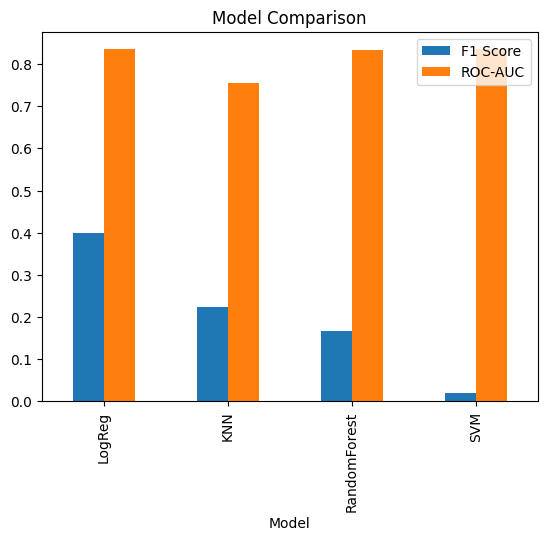

In [11]:
import matplotlib.pyplot as plt

results_df.set_index("Model")[["F1 Score", "ROC-AUC"]].plot(kind="bar")

plt.title("Model Comparison")
plt.show()

In [ ]:
import pickle

# Save each trained model
for name, model in trained_models.items():
    filename = f"../exports/{name.lower()}.sav"
    pickle.dump(model, open(filename, "wb"))
    print(f"Saved {name} to {filename}")

# Save the scaler too
pickle.dump(scaler, open("../exports/scaler.sav", "wb"))
print("Saved scaler")

Saved LogReg to logreg.sav
Saved KNN to knn.sav
Saved RandomForest to randomforest.sav
Saved SVM to svm.sav
Saved scaler


## Final Model Selection

The models were evaluated using Accuracy, F1-score, and ROC-AUC.

Due to class imbalance, F1-score and ROC-AUC were prioritized over accuracy.

The best performing model was selected based on its ability to correctly identify positive class (Response = 1).